In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score


In [2]:
df = pd.read_csv("dbscan.csv")

numeric_features = [
    "feature_x",
    "feature_y",
    "signal_strength",
    "transaction_amount",
    "session_minutes"
]

categorical_features = [
    "device_type",
    "region",
    "membership"
]

# 2. Define preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [3]:
X_processed = preprocessor.fit_transform(df)

# Convert sparse output to dense for this modest dataset
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("Processed shape:", X_processed.shape)

# 4. Estimate a candidate epsilon
min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)
neighbors.fit(X_processed)

distances, _ = neighbors.kneighbors(X_processed)
k_distances = np.sort(distances[:, -1])

Processed shape: (1206, 15)


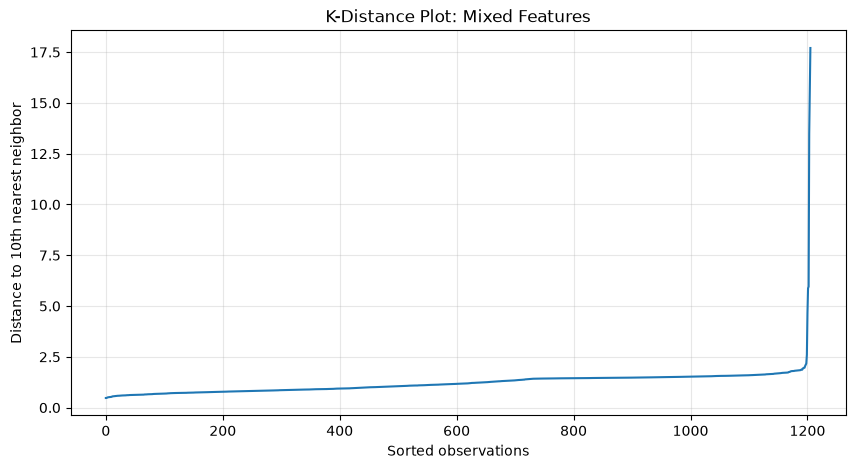

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title("K-Distance Plot: Mixed Features")
plt.xlabel("Sorted observations")
plt.ylabel("Distance to 10th nearest neighbor")
plt.grid(alpha=0.3)
plt.show()

In [5]:
model = DBSCAN(
    eps=1.5,
    min_samples=min_samples,
    metric="euclidean"
)

labels = model.fit_predict(X_processed)
df["cluster"] = labels

In [7]:
n_clusters = len(set(labels) - {-1})
noise_count = int(np.sum(labels == -1))

print("Number of clusters:", n_clusters)
print("Noise points:", noise_count)
print("Noise percentage:", round(
    noise_count / len(labels) * 100, 2
))

print("\nCluster distribution:")
print(df["cluster"].value_counts().sort_index())

Number of clusters: 1
Noise points: 41
Noise percentage: 3.4

Cluster distribution:
cluster
-1      41
 0    1165
Name: count, dtype: int64


In [9]:
non_noise = labels != -1
non_noise_labels = labels[non_noise]

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(
        X_processed[non_noise],
        non_noise_labels
    )
    print("Silhouette score (non-noise only):", round(score, 3))
else:
    print("Silhouette score unavailable: need at least 2 non-noise clusters.")

Silhouette score unavailable: need at least 2 non-noise clusters.


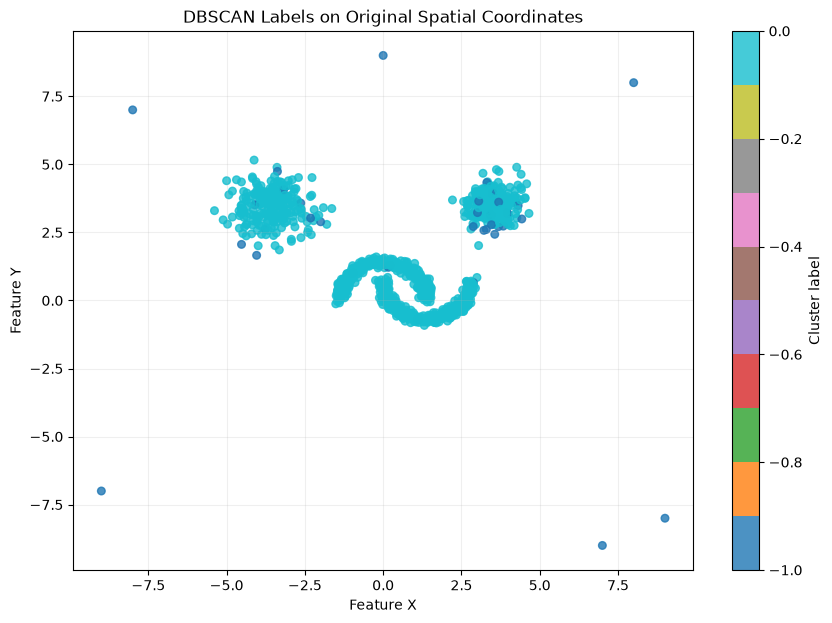

In [10]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df["feature_x"],
    df["feature_y"],
    c=labels,
    cmap="tab10",
    s=30,
    alpha=0.8
)

plt.colorbar(scatter, label="Cluster label")
plt.title("DBSCAN Labels on Original Spatial Coordinates")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.grid(alpha=0.2)
plt.show()


In [11]:
df.to_csv("dbscan_clustered_results.csv", index=False)
print("Saved dbscan_clustered_results.csv")

Saved dbscan_clustered_results.csv
